# CS467 Advanced AI (2026-2027) - Assignment 15
## Mini-Project MP-A08: Tech Blog and News Article Recommender
- **Student**: Huỳnh Tấn Gia Huy
- **Student ID**: 29211458346
- **Section**: CS467A (No. 08)
- **Instructor**: Puri Vikram
- **Institution**: Duy Tan University

This notebook provides an interactive walkthrough of the Natural Language Processing (NLP) pipeline, TF-IDF vectorization, recommendation algorithms (Popularity, Content-Based, User-Based Collaborative Filtering, and Hybrid), the 3 required test cases, and empirical evaluation results.


In [1]:
import sys
from pathlib import Path

# Locate project root dynamically
curr = Path.cwd().resolve()
candidates = [curr, curr / "cs467-miniproject-29211458346", curr.parent, curr.parent / "cs467-miniproject-29211458346"]
PROJECT_ROOT = None
for c in candidates:
    if (c / "data" / "items.csv").exists() and (c / "src").exists():
        PROJECT_ROOT = c
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate project root containing data/items.csv and src/")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

from src.nlp_pipeline import clean_text, tokenize, remove_stopwords, preprocess, NLPPipeline
from src.recommender import (
    PopularityRecommender,
    ContentBasedRecommender,
    UserBasedCF,
    HybridRecommender
)

# Load datasets
items_df = pd.read_csv(PROJECT_ROOT / "data" / "items.csv")
ratings_df = pd.read_csv(PROJECT_ROOT / "data" / "ratings.csv")

print(f"Project root: {PROJECT_ROOT}")
print(f"Items loaded: {len(items_df)} articles across 9 topics.")
print(f"Ratings loaded: {len(ratings_df)} user ratings from 14 users.")

# Compute measured sparsity
total_possible = 14 * 45
sparsity = (1.0 - (len(ratings_df) / total_possible)) * 100.0
print(f"Interaction Matrix Sparsity: {sparsity:.2f}% missing values")
display(items_df.head(3))


Project root: C:\Users\ADMIN\Downloads\tri_tuenhantao\cs467-miniproject-29211458346
Items loaded: 45 articles across 9 topics.
Ratings loaded: 284 user ratings from 14 users.
Interaction Matrix Sparsity: 54.92% missing values


,item_id,headline,topic,publish_date,summary_text,tags
0,A001,Zero-Day Privilege Escalation Vulnerability Di...,Cybersecurity,2026-02-14,Security researchers uncovered a heap out-of-b...,linux;kernel;vulnerability;zero-day;privilege-...
1,A002,Black Basta Ransomware Syndicate Deploys Novel...,Cybersecurity,2026-03-02,Threat intelligence analysts detected updated ...,ransomware;cybersecurity;linux;malware;threat-...
2,A003,Memory-Safe Hardening Frameworks Mandated for ...,Cybersecurity,2026-01-28,Federal cybersecurity regulators published new...,security;hardening;memory-safety;infrastructur...


## 1. NLP Preprocessing & Domain Vocabulary Preservation
The pipeline preserves key tech domain tokens (such as `linux`, `ai`, `llm`, `cpu`, `gpu`) while stripping standard English stopwords and extra punctuation.


In [2]:
sample_text = "Deploying open-source LLMs on local Linux laptops with hardware-accelerated AI and GPU runtimes!"
print("Raw Input Text:")
print(sample_text)
print("\nCleaned Text:")
print(clean_text(sample_text))
print("\nTokenized:")
print(tokenize(clean_text(sample_text)))
print("\nAfter Domain-Preserving Stopword Removal:")
print(remove_stopwords(tokenize(clean_text(sample_text))))
print("\nEnd-to-End Preprocessed Document:")
print(preprocess(sample_text))


Raw Input Text:
Deploying open-source LLMs on local Linux laptops with hardware-accelerated AI and GPU runtimes!

Cleaned Text:
deploying open source llms on local linux laptops with hardware accelerated ai and gpu runtimes

Tokenized:
['deploying', 'open', 'source', 'llms', 'on', 'local', 'linux', 'laptops', 'with', 'hardware', 'accelerated', 'ai', 'and', 'gpu', 'runtimes']

After Domain-Preserving Stopword Removal:
['deploying', 'open', 'source', 'llms', 'local', 'linux', 'laptops', 'hardware', 'accelerated', 'ai', 'gpu', 'runtimes']

End-to-End Preprocessed Document:
deploying open source llms local linux laptops hardware accelerated ai gpu runtimes


## 2. TF-IDF Vectorization & Article Indexing
Item documents are formed by `headline * 2 + summary_text + tags`, emphasizing headline terms. We fit a `TfidfVectorizer(ngram_range=(1,2), sublinear_tf=True)` with L2 normalization.


In [3]:
pipeline = NLPPipeline(ngram_range=(1, 2), sublinear_tf=True)
item_matrix = pipeline.fit_transform(items_df)

print(f"Fitted Item Matrix Shape: {item_matrix.shape} (45 items x {item_matrix.shape[1]} unigram/bigram features)")
print(f"Matrix L2 Norm verification: {np.linalg.norm(item_matrix[0]):.4f}")


Fitted Item Matrix Shape: (45, 3655) (45 items x 3655 unigram/bigram features)
Matrix L2 Norm verification: 1.0000


## 3. Test Case 1: Reader Profile (U01 - Cybersecurity & Linux Specialist)
U01 has known interest in Cybersecurity and Linux. We build their rating-weighted profile vector and recommend Top-5 unread articles using Content-Based, Popularity, Collaborative Filtering, and Hybrid methods.


In [4]:
# Build U01 taste profile
u01_profile = pipeline.build_user_profile("U01", ratings_df)
top_kw = pipeline.get_top_user_keywords(u01_profile, top_n=6)
print("Learned Top Keywords for U01 Profile:")
for term, weight in top_kw:
    print(f"  - {term}: {weight:.4f}")

cb_rec = ContentBasedRecommender(items_df, ratings_df, pipeline)
pop_rec = PopularityRecommender(items_df, ratings_df)
cf_rec = UserBasedCF(items_df, ratings_df, k_neighbors=5)
hyb_rec = HybridRecommender(cb_rec, cf_rec, alpha=0.75)

print("\n[1.1] Content-Based Top-5 Unread Recommendations for U01:")
display(cb_rec.recommend_for_user("U01", top_k=5, exclude_seen=True))

print("\n[1.2] Hybrid Recommender (alpha=0.75) Top-5 Unread for U01:")
display(hyb_rec.recommend_for_user("U01", top_k=5, exclude_seen=True))


Learned Top Keywords for U01 Profile:
  - linux: 0.1476
  - hardening: 0.1308
  - security: 0.1182
  - vulnerability: 0.1158
  - privilege: 0.1045
  - memory: 0.1041



[1.1] Content-Based Top-5 Unread Recommendations for U01:


,item_id,headline,topic,score,keywords
0,A010,Debian Releases Landmark Security Overhaul Mit...,Linux,0.103384,"security, kernel, hardening, linux, channel"
1,A002,Black Basta Ransomware Syndicate Deploys Novel...,Cybersecurity,0.074184,"linux, hardening, kernel, systems, security"
2,A007,Arch Linux and Fedora Adopt Unified Kernel Ima...,Linux,0.073030,"linux, kernel, hardening, security, vulnerabil..."
3,A004,State-Sponsored APT Groups Exploit Unpatched E...,Cybersecurity,0.072401,"day, zero day, zero, security, defense"
4,A009,Next-Generation Storage Architectures in Linux...,Linux,0.067328,"linux, kernel, linux kernel, performance, sysa..."



[1.2] Hybrid Recommender (alpha=0.75) Top-5 Unread for U01:


,item_id,headline,topic,score,keywords
0,A010,Debian Releases Landmark Security Overhaul Mit...,Linux,0.963597,"security, kernel, hardening, linux, channel"
1,A007,Arch Linux and Fedora Adopt Unified Kernel Ima...,Linux,0.697320,"linux, kernel, hardening, security, vulnerabil..."
2,A004,State-Sponsored APT Groups Exploit Unpatched E...,Cybersecurity,0.696862,"day, zero day, zero, security, defense"
3,A009,Next-Generation Storage Architectures in Linux...,Linux,0.646369,"linux, kernel, linux kernel, performance, sysa..."
4,A002,Black Basta Ransomware Syndicate Deploys Novel...,Cybersecurity,0.608492,"linux, hardening, kernel, systems, security"


## 4. Test Case 2: Natural Language Query Search
Free-form query: `"open source large language models on laptop"`
Vectorized through the same fitted TF-IDF vocabulary and matched via cosine similarity.


In [5]:
query = "open source large language models on laptop"
print(f'Search Query: "{query}"')
query_results = cb_rec.recommend_for_query(query, top_k=5)
display(query_results[["item_id", "headline", "topic", "score", "keywords"]])


Search Query: "open source large language models on laptop"


,item_id,headline,topic,score,keywords
0,A014,Privacy-Preserving AI: Deploying Open-Source L...,Open-Source LLMs,0.296739,"language models, open source, source, language..."
1,A012,Small Open-Weight Language Models Achieve Pari...,Open-Source LLMs,0.271899,"language models, open, language, models, laptop"
2,A015,Low-Latency Speculative Decoding Enables High-...,Open-Source LLMs,0.176650,"open source, source, open, laptop"
3,A011,Running Quantized Open-Source LLMs on Consumer...,Open-Source LLMs,0.156625,"open, open source, source, laptop, models"
4,A013,4-Bit GGUF Quantization Techniques for Efficie...,Open-Source LLMs,0.143421,"laptop, open source, source, open"


## 5. Test Case 3: Cold-Start Unrated New Article
Handling a completely new article with zero historical ratings:
`"Critical zero-day vulnerability discovered in the Linux kernel allows privilege escalation; maintainers rush emergency patch"`


In [6]:
headline = "Critical zero-day vulnerability discovered in the Linux kernel allows privilege escalation; maintainers rush emergency patch"
summary = "Security researchers uncovered a critical zero-day memory vulnerability inside the Linux kernel allowing unprivileged local users to achieve root execution. Kernel maintainers have released an emergency security patch."
tags = "linux;kernel;vulnerability;zero-day;privilege-escalation;patch;security"

sim_articles, top_readers = cb_rec.recommend_for_new_article(headline, summary, tags, top_k=5, top_users_k=3)

print("Top-5 Most Similar Existing Articles in Catalog:")
display(sim_articles[["item_id", "headline", "topic", "score", "keywords"]])

print("\nTop-3 Likely Readers for this New Article:")
display(top_readers)


Top-5 Most Similar Existing Articles in Catalog:


,item_id,headline,topic,score,keywords
0,A001,Zero-Day Privilege Escalation Vulnerability Di...,Cybersecurity,0.649879,"vulnerability, linux kernel, kernel, day, zero..."
1,A008,Modern Linux Server Hardening: Best Practices ...,Linux,0.129106,"privilege, linux, privilege escalation, escala..."
2,A005,Automated Vulnerability Auditing Identifies Cr...,Cybersecurity,0.116146,"vulnerability, critical, maintainers, patch, l..."
3,A010,Debian Releases Landmark Security Overhaul Mit...,Linux,0.107048,"kernel, security, maintainers, patch, security..."
4,A003,Memory-Safe Hardening Frameworks Mandated for ...,Cybersecurity,0.085922,"critical, day, zero day, zero, memory"



Top-3 Likely Readers for this New Article:


,user_id,score,keywords
0,U01,0.375432,"vulnerability, linux, day, zero day, kernel"
1,U09,0.268464,"linux, kernel, vulnerability, linux kernel, ze..."
2,U14,0.212260,"kernel, linux, security, privilege, zero"


## 6. Evaluation Benchmark Results & Visualizations
20-seed Monte Carlo per-user hold-out evaluation summary and generated high-resolution charts.


=== EVALUATION SUMMARY ACROSS 20 RANDOM SEEDS ===

,Metric,Mean,Std,Min,Max
0,Popularity,0.040714,0.018115,0.000000,0.071429
1,Content-Based,0.072857,0.017891,0.042857,0.100000
2,User-Based CF,0.053571,0.023577,0.014286,0.100000
3,Hybrid (alpha=0.00),0.053571,0.023577,0.014286,0.100000
4,Hybrid (alpha=0.25),0.060714,0.016631,0.028571,0.085714
5,Hybrid (alpha=0.50),0.074286,0.019444,0.042857,0.114286
6,Hybrid (alpha=0.75),0.075000,0.017265,0.042857,0.100000
7,Hybrid (alpha=1.00),0.072857,0.017891,0.042857,0.100000
8,CF_RMSE,1.534014,0.139871,1.300657,1.787224
9,CF_MAE,1.297903,0.131377,1.104764,1.550502



--- Visualizations ---
Plot: rating_and_topic_distribution.png


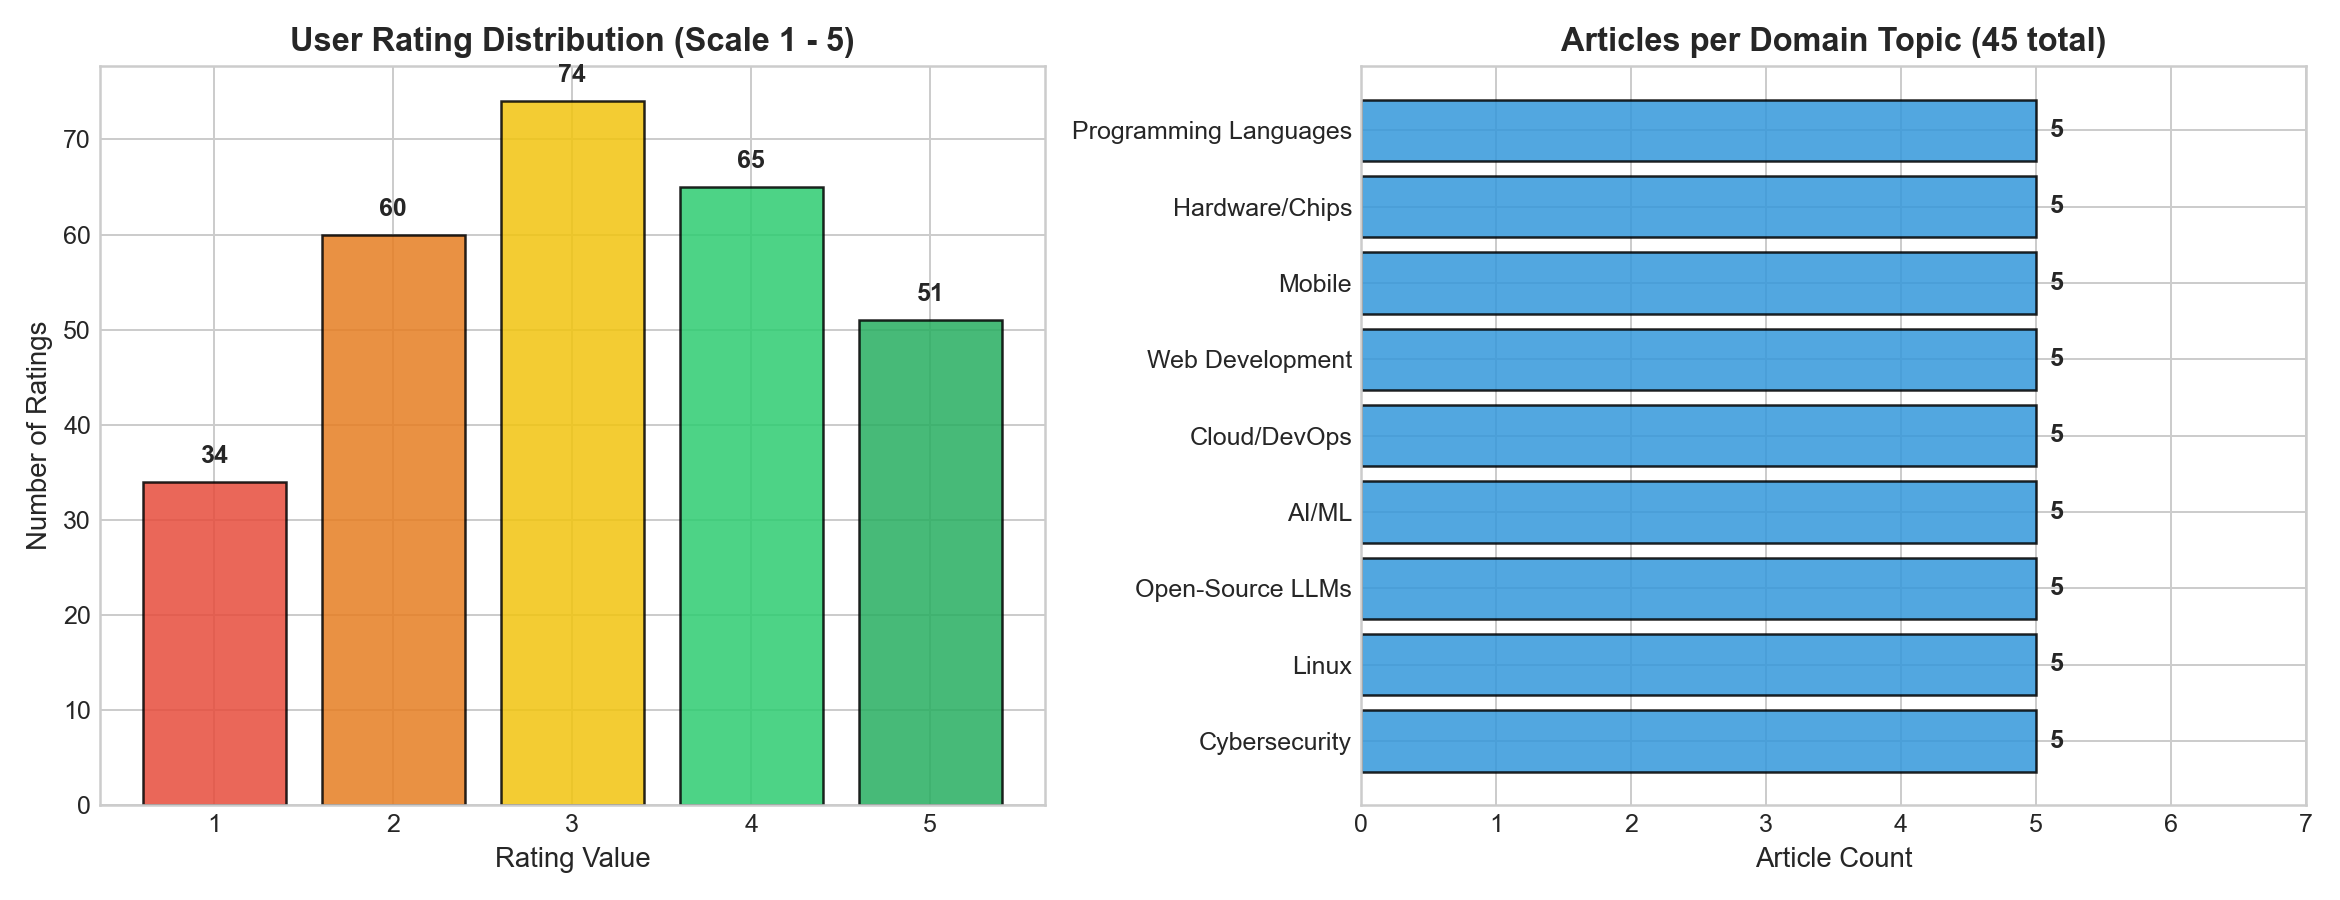

Plot: precision_at_5_comparison.png


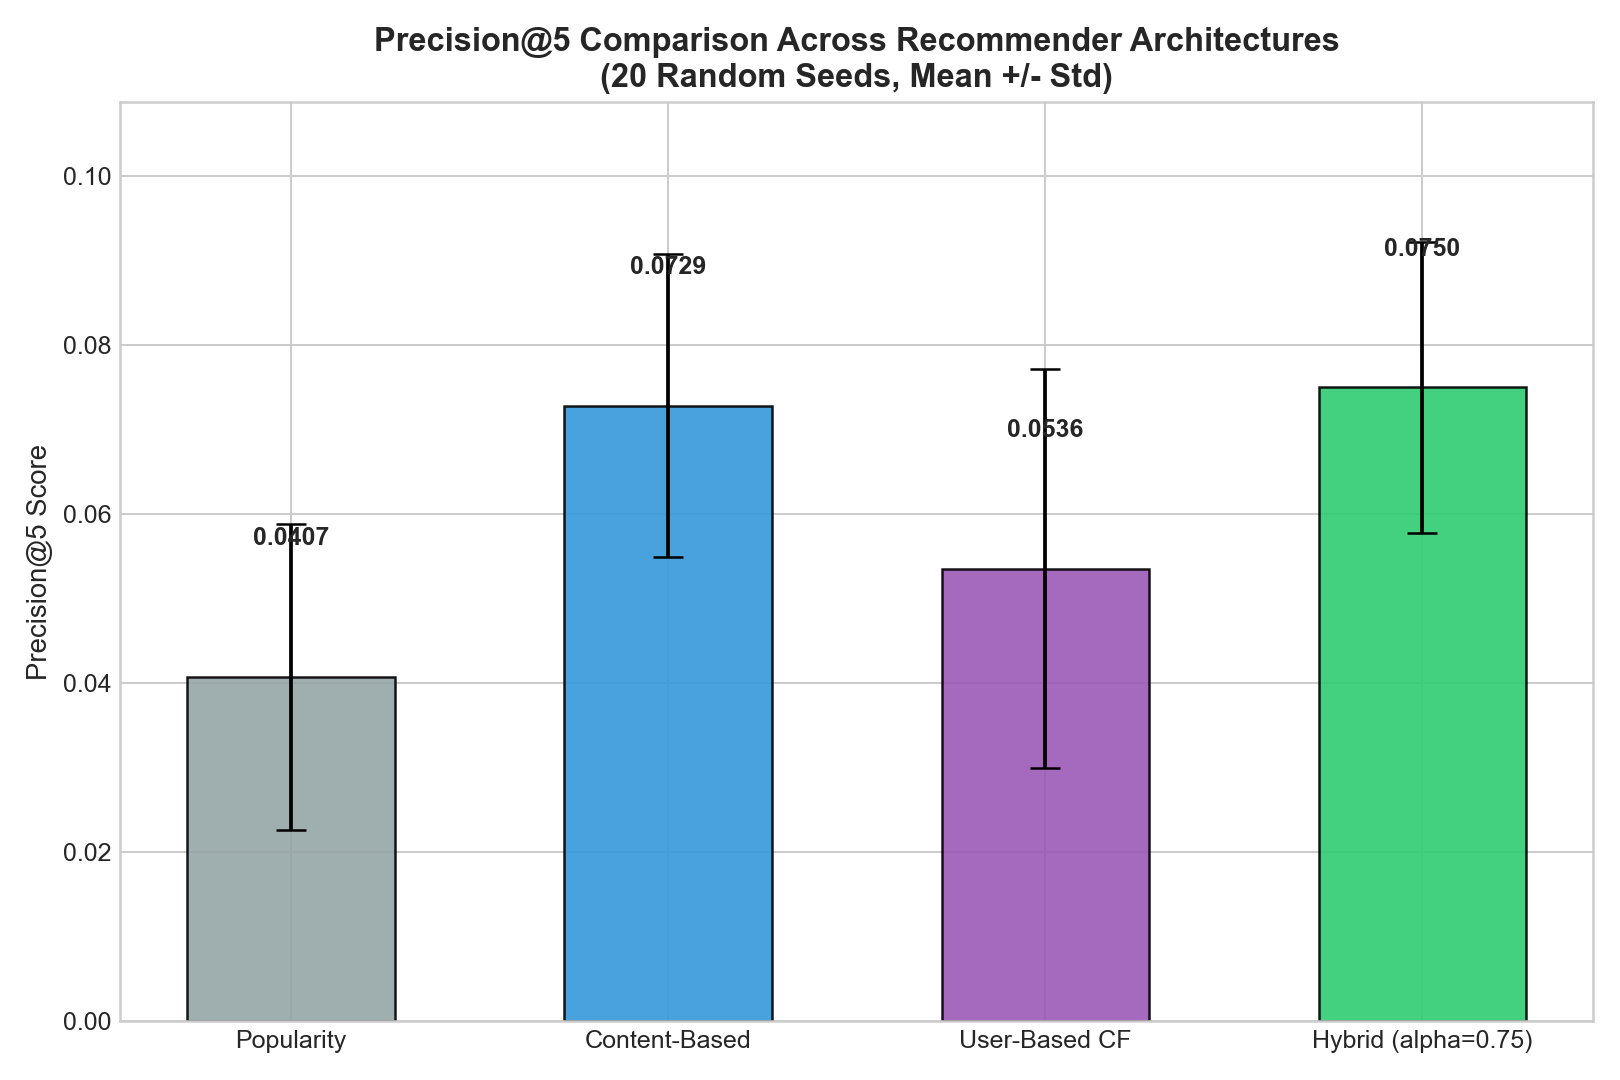

Plot: hybrid_alpha_sweep.png


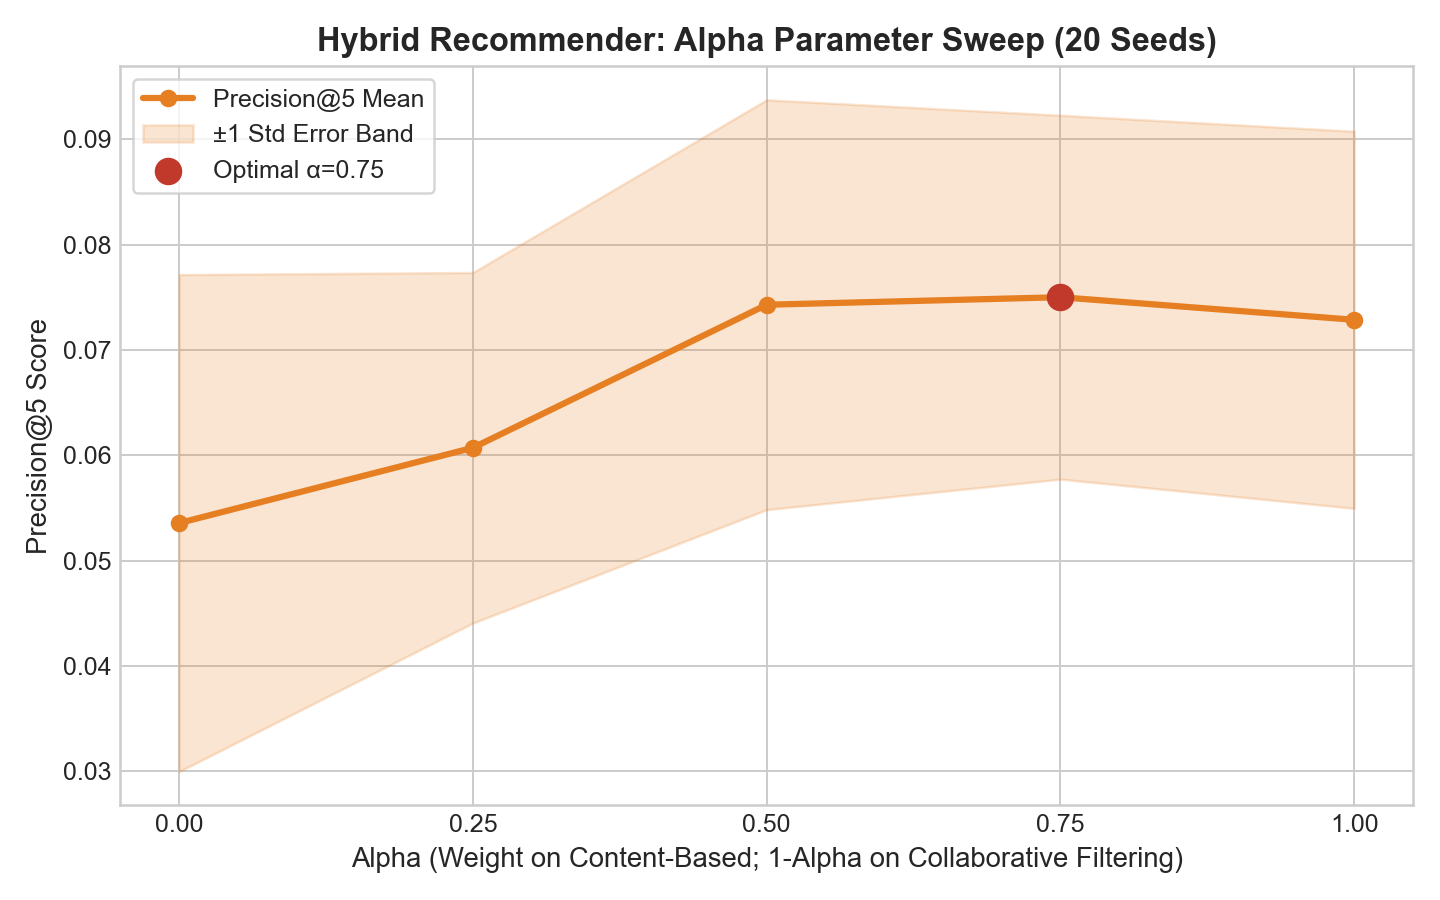

Plot: user_item_sparsity.png


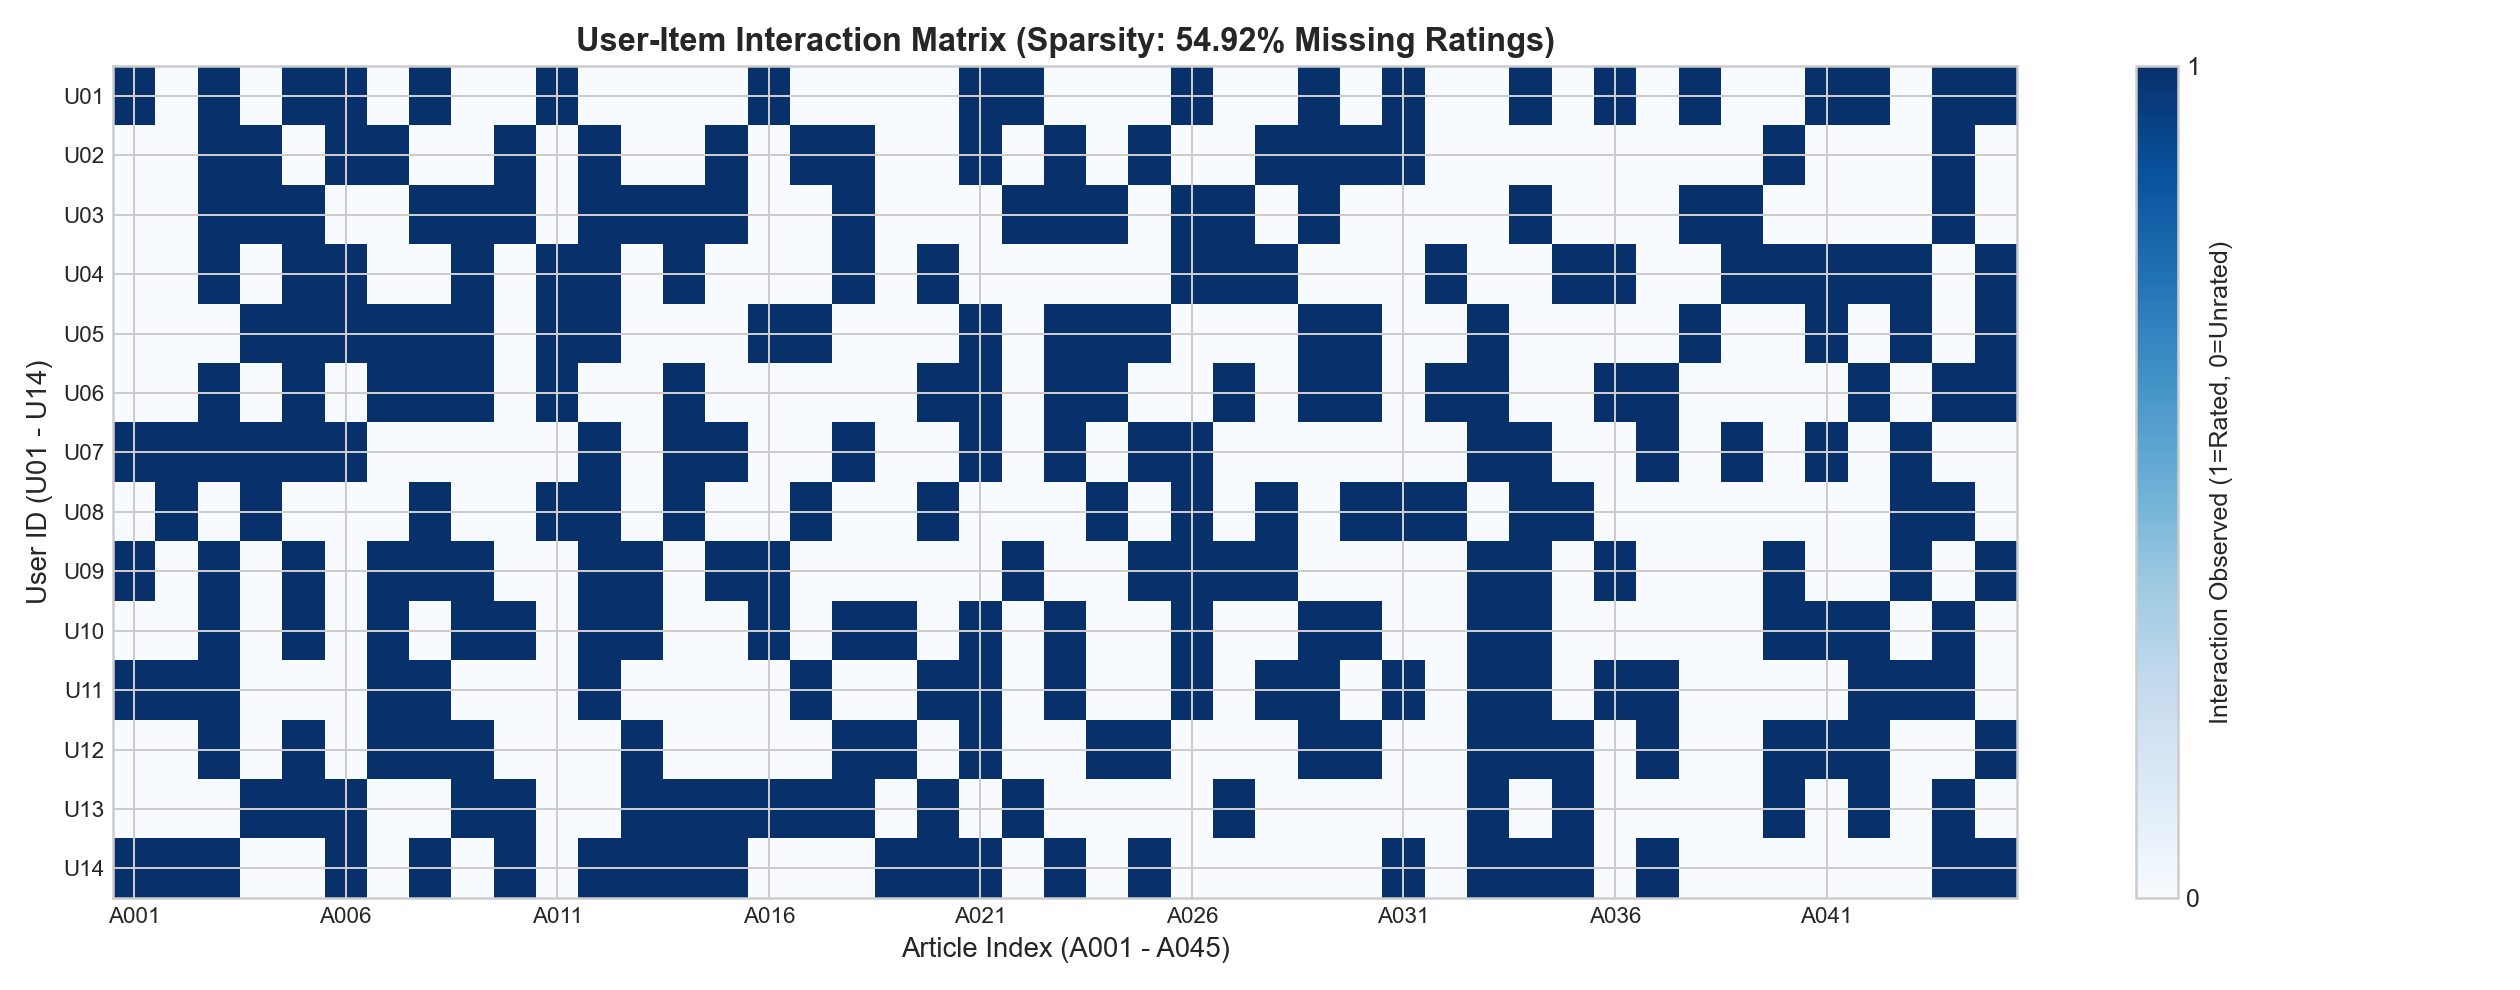

In [7]:
eval_results_path = PROJECT_ROOT / "results" / "evaluation_results.csv"
if eval_results_path.exists():
    eval_df = pd.read_csv(eval_results_path)
    print("=== EVALUATION SUMMARY ACROSS 20 RANDOM SEEDS ===")
    display(eval_df)

print("\n--- Visualizations ---")
chart_files = [
    "rating_and_topic_distribution.png",
    "precision_at_5_comparison.png",
    "hybrid_alpha_sweep.png",
    "user_item_sparsity.png"
]
for fname in chart_files:
    fpath = PROJECT_ROOT / "results" / fname
    if fpath.exists():
        print(f"Plot: {fname}")
        display(Image(filename=str(fpath), width=750))
